# Task 3: Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Goal:** predict which telecom customers will churn, handling the class imbalance and reaching a **ROC-AUC above 0.80**.

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns). Target: `Churn` (Yes/No).

**Workflow**
1. Load and clean the data (`TotalCharges` to numeric, handle nulls)
2. Explore the data and check class balance
3. Stratified train/test split
4. Preprocess: `OneHotEncoder` for categoricals, `StandardScaler` for numerics
5. Balance classes with **SMOTE** (applied only inside training folds, to avoid leakage) and compare with **class weighting**
6. Train Random Forest and XGBoost with 5-fold cross-validation, then tune lightly
7. Evaluate on the held-out test set: ROC curve, confusion matrix, classification report
8. Plot the top 10 feature importances

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 1. Load the data

In [2]:
df = pd.read_csv("telco_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 2. Clean the data

`TotalCharges` is stored as text because 11 rows contain a blank space. Those customers have `tenure = 0` (brand new, not yet billed), so a `TotalCharges` of 0 is the logical value.

In [4]:
# Convert TotalCharges to numeric; blanks become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Null TotalCharges:", df["TotalCharges"].isna().sum())
print("Their tenure values:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

# New customers (tenure 0) have not been billed yet, so fill with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is only an identifier
df = df.drop(columns="customerID")

# Encode the target
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Remaining nulls:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Null TotalCharges: 11
Their tenure values: [0]
Remaining nulls: 0
Duplicate rows: 22


## 3. Exploratory analysis

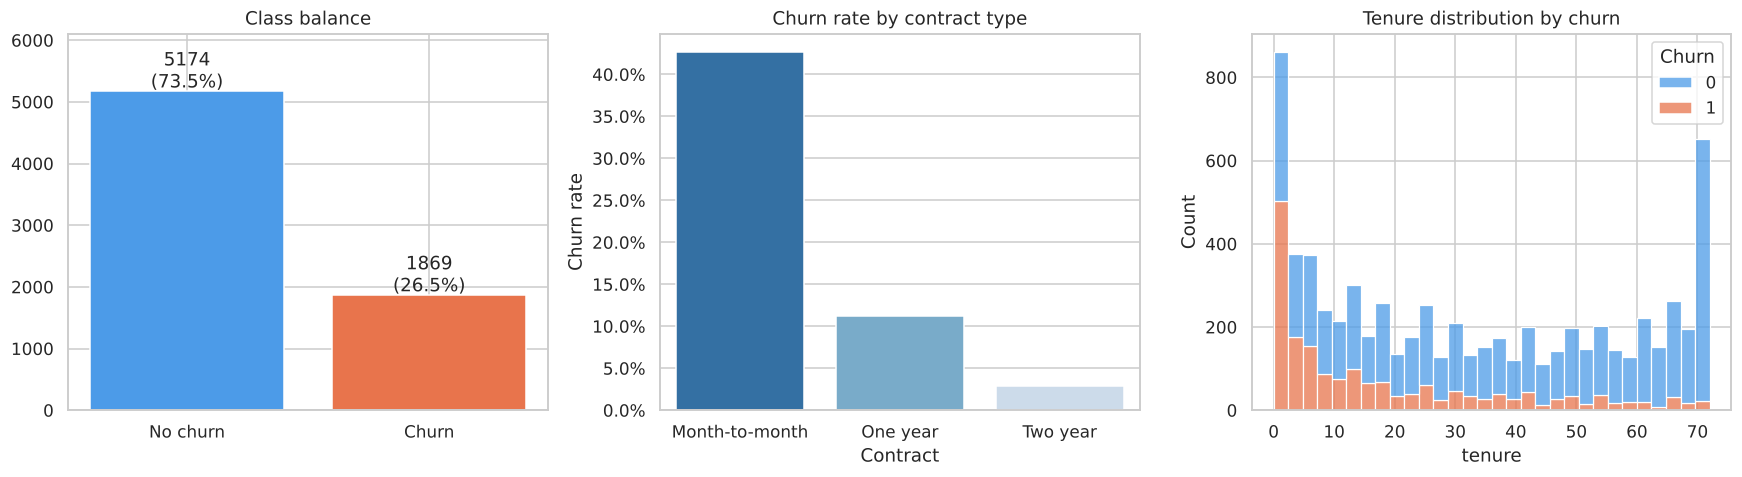

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Class balance
counts = df["Churn"].value_counts().sort_index()
axes[0].bar(["No churn", "Churn"], counts.values, color=["#4C9BE8", "#E8744C"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v}\n({v/len(df):.1%})", ha="center")
axes[0].set_title("Class balance")
axes[0].set_ylim(0, counts.max() * 1.18)

# Churn rate by contract
contract = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
sns.barplot(x=contract.index, y=contract.values, ax=axes[1], palette="Blues_r")
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))

# Tenure distribution by churn
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack",
             palette=["#4C9BE8", "#E8744C"], ax=axes[2])
axes[2].set_title("Tenure distribution by churn")

plt.tight_layout()
plt.show()

**Observations**
- The data is imbalanced: only about **26.5%** of customers churn, so plain accuracy would be misleading (always predicting "No churn" already gives ~73%). That is why we optimise **ROC-AUC** and look at recall.
- Month-to-month customers churn far more than customers on one or two year contracts.
- Churn is concentrated among customers with short tenure.

## 4. Train/test split and preprocessing

We hold out 20% of the data (stratified, so both sets keep the same churn rate). All preprocessing and SMOTE live inside pipelines, so they are fitted on training data only.

In [6]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " churn rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  " churn rate:", round(y_test.mean(), 3))

numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [c for c in X.columns if c not in numeric_features]
print("\nNumeric:", numeric_features)
print("Categorical:", len(categorical_features), "columns")

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

Train: (5634, 19)  churn rate: 0.265
Test:  (1409, 19)  churn rate: 0.265

Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: 16 columns


## 5. Handling imbalance: SMOTE vs class weighting

We compare both strategies with 5-fold stratified cross-validation (ROC-AUC) on the training set:

| Strategy | Random Forest | XGBoost |
|---|---|---|
| **SMOTE** | oversample churners inside each training fold | oversample churners inside each training fold |
| **Class weighting** | `class_weight="balanced"` | `scale_pos_weight = negatives / positives` |

SMOTE sits inside an `imblearn` pipeline, so synthetic samples are only created from the training part of each fold and never leak into validation data.

In [7]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print(f"scale_pos_weight = {spw:.2f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rf(**kw):
    return RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **kw)

def xgb(**kw):
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                         colsample_bytree=0.8, eval_metric="logloss",
                         random_state=RANDOM_STATE, n_jobs=-1, **kw)

candidates = {
    "Random Forest + SMOTE": ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", rf())]),
    "Random Forest + class weight": Pipeline([("prep", preprocessor), ("model", rf(class_weight="balanced"))]),
    "XGBoost + SMOTE": ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)), ("model", xgb())]),
    "XGBoost + scale_pos_weight": Pipeline([("prep", preprocessor), ("model", xgb(scale_pos_weight=spw))]),
}

rows = []
for name, pipe in candidates.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "Std": scores.std()})
    print(f"{name:32s} ROC-AUC = {scores.mean():.4f} (+/- {scores.std():.4f})")

cv_results = pd.DataFrame(rows).sort_values("CV ROC-AUC (mean)", ascending=False).reset_index(drop=True)
cv_results

scale_pos_weight = 2.77


Random Forest + SMOTE            ROC-AUC = 0.8194 (+/- 0.0107)


Random Forest + class weight     ROC-AUC = 0.8228 (+/- 0.0116)


XGBoost + SMOTE                  ROC-AUC = 0.8426 (+/- 0.0096)


XGBoost + scale_pos_weight       ROC-AUC = 0.8440 (+/- 0.0104)


,Model,CV ROC-AUC (mean),Std
0,XGBoost + scale_pos_weight,0.844033,0.010404
1,XGBoost + SMOTE,0.842565,0.009559
2,Random Forest + class weight,0.822829,0.011616
3,Random Forest + SMOTE,0.819373,0.010687


## 6. Light hyperparameter tuning

We tune each algorithm with `RandomizedSearchCV` (SMOTE pipelines, 5-fold CV, scoring on ROC-AUC).

In [8]:
rf_pipe = ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)),
                       ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])
rf_params = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [6, 8, 12, None],
    "model__min_samples_leaf": [1, 3, 5, 10],
    "model__max_features": ["sqrt", 0.3, 0.5],
}

xgb_pipe = ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)),
                        ("model", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1))])
xgb_params = {
    "model__n_estimators": [200, 300, 500],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [3, 4, 5, 6],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
}

searches = {}
for name, pipe, params in [("Random Forest", rf_pipe, rf_params), ("XGBoost", xgb_pipe, xgb_params)]:
    s = RandomizedSearchCV(pipe, params, n_iter=12, scoring="roc_auc", cv=cv,
                           random_state=RANDOM_STATE, n_jobs=1, refit=True)
    s.fit(X_train, y_train)
    searches[name] = s
    print(f"{name}: best CV ROC-AUC = {s.best_score_:.4f}")
    print("   best params:", {k.replace('model__', ''): v for k, v in s.best_params_.items()})

Random Forest: best CV ROC-AUC = 0.8432
   best params: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12}


XGBoost: best CV ROC-AUC = 0.8460
   best params: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


## 7. Evaluation on the held-out test set

In [9]:
results = {}
for name, s in searches.items():
    model = s.best_estimator_
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {"model": model, "proba": proba, "pred": pred, "auc": roc_auc_score(y_test, proba)}
    print(f"===== {name} =====")
    print(f"Test ROC-AUC: {results[name]['auc']:.4f}")
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"], digits=3))

===== Random Forest =====
Test ROC-AUC: 0.8386
              precision    recall  f1-score   support

    No churn      0.885     0.789     0.835      1035
       Churn      0.551     0.717     0.623       374

    accuracy                          0.770      1409
   macro avg      0.718     0.753     0.729      1409
weighted avg      0.797     0.770     0.778      1409

===== XGBoost =====
Test ROC-AUC: 0.8435
              precision    recall  f1-score   support

    No churn      0.881     0.801     0.839      1035
       Churn      0.560     0.701     0.622       374

    accuracy                          0.774      1409
   macro avg      0.720     0.751     0.731      1409
weighted avg      0.796     0.774     0.782      1409



### ROC curves

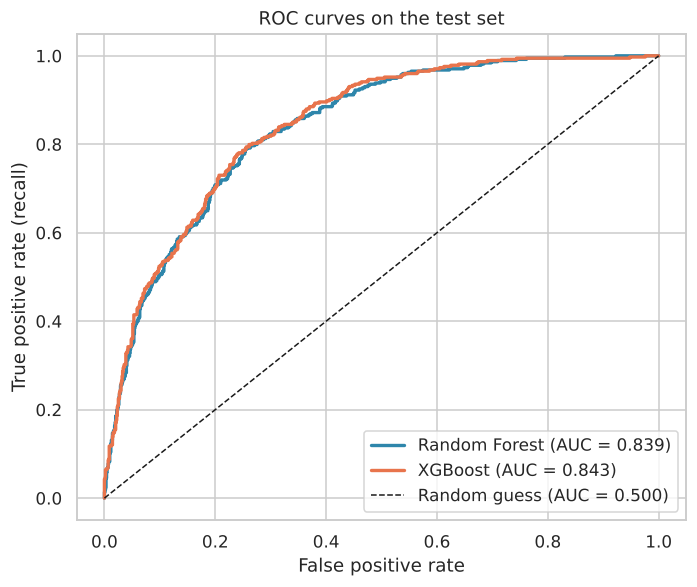

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = {"Random Forest": "#2E86AB", "XGBoost": "#E8744C"}
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["proba"])
    ax.plot(fpr, tpr, lw=2.2, color=colors[name], label=f"{name} (AUC = {r['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.500)")
ax.axhline(0, color="none")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Confusion matrices

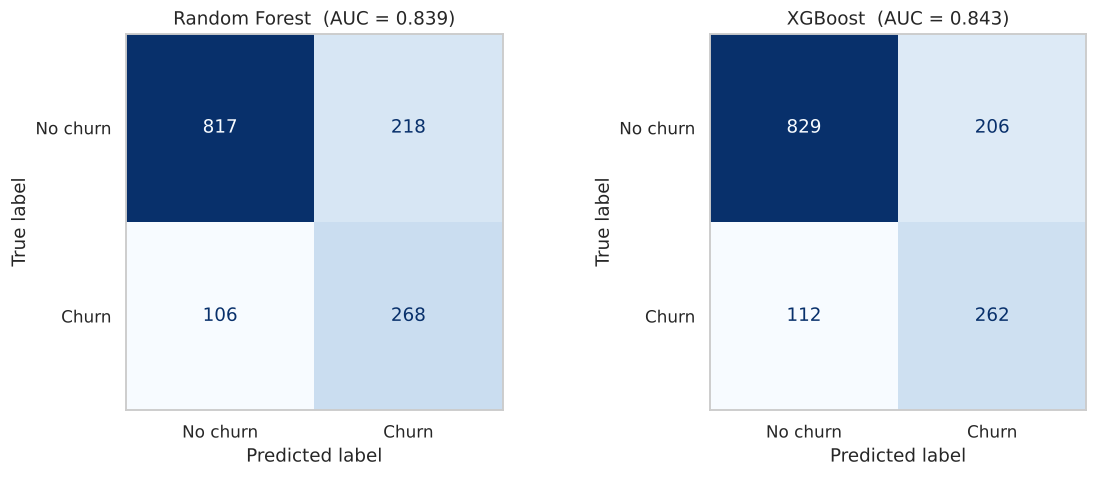

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r["pred"])
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}  (AUC = {r['auc']:.3f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

### Side-by-side summary

In [12]:
summary = []
for name, r in results.items():
    rep = classification_report(y_test, r["pred"], output_dict=True)
    summary.append({
        "Model": name,
        "ROC-AUC": round(r["auc"], 4),
        "Accuracy": round(rep["accuracy"], 4),
        "Churn precision": round(rep["1"]["precision"], 4),
        "Churn recall": round(rep["1"]["recall"], 4),
        "Churn F1": round(rep["1"]["f1-score"], 4),
    })
summary_df = pd.DataFrame(summary)
display(summary_df)
print("Target ROC-AUC > 0.80 reached:", bool((summary_df['ROC-AUC'] > 0.80).all()))

,Model,ROC-AUC,Accuracy,Churn precision,Churn recall,Churn F1
0,Random Forest,0.8386,0.7700,0.5514,0.7166,0.6233
1,XGBoost,0.8435,0.7743,0.5598,0.7005,0.6223


Target ROC-AUC > 0.80 reached: True


## 8. Top 10 feature importances

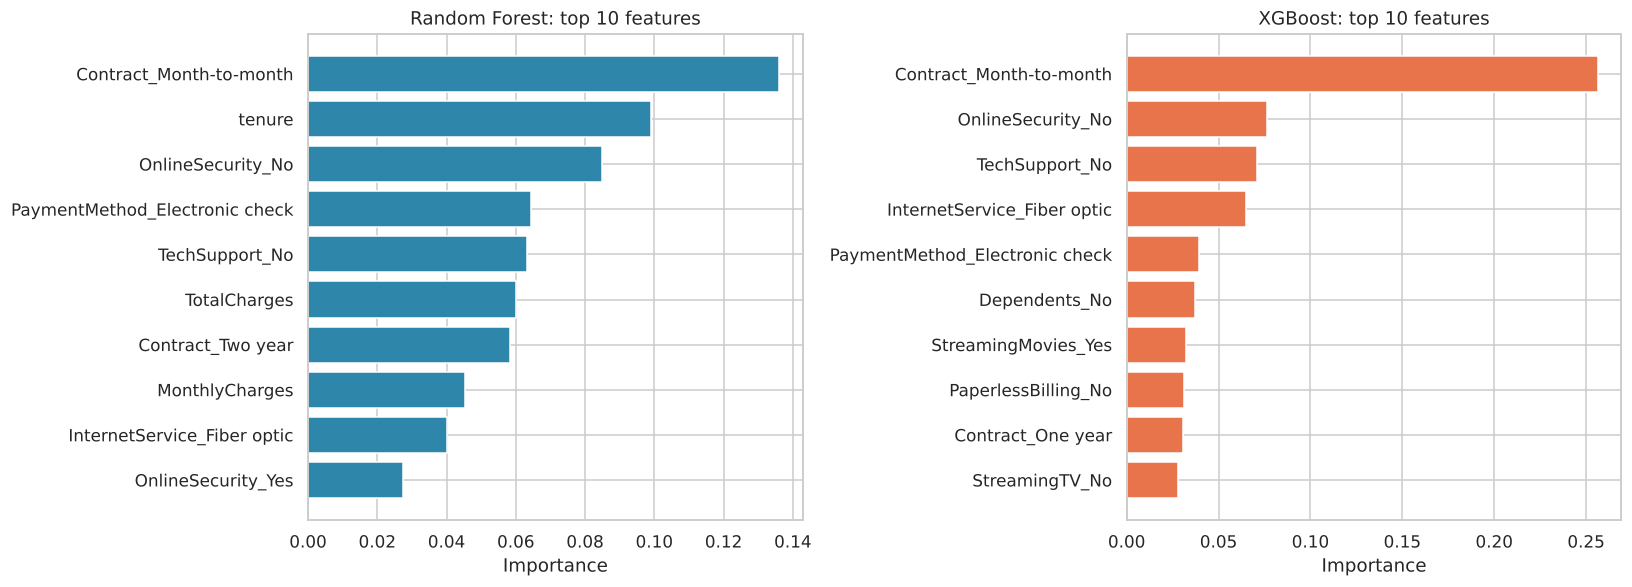


Random Forest
Contract_Month-to-month           0.1361
tenure                            0.0990
OnlineSecurity_No                 0.0848
PaymentMethod_Electronic check    0.0643
TechSupport_No                    0.0631
TotalCharges                      0.0602
Contract_Two year                 0.0584
MonthlyCharges                    0.0452
InternetService_Fiber optic       0.0401
OnlineSecurity_Yes                0.0273

XGBoost
Contract_Month-to-month           0.2564
OnlineSecurity_No                 0.0766
TechSupport_No                    0.0709
InternetService_Fiber optic       0.0648
PaymentMethod_Electronic check    0.0396
Dependents_No                     0.0372
StreamingMovies_Yes               0.0320
PaperlessBilling_No               0.0310
Contract_One year                 0.0307
StreamingTV_No                    0.0281


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top_features = {}
for ax, (name, r) in zip(axes, results.items()):
    fitted = r["model"]
    names = fitted.named_steps["prep"].get_feature_names_out()
    names = [n.replace("num__", "").replace("cat__", "") for n in names]
    imp = pd.Series(fitted.named_steps["model"].feature_importances_, index=names)
    top = imp.sort_values(ascending=False).head(10)[::-1]
    top_features[name] = top[::-1]
    ax.barh(top.index, top.values, color=colors[name])
    ax.set_title(f"{name}: top 10 features")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

for name, top in top_features.items():
    print(f"\n{name}")
    print(top.round(4).to_string())

## 9. Conclusions

- **Both models clear the ROC-AUC > 0.80 target** on unseen data (see the summary table above).
- **SMOTE and class weighting are close in ROC-AUC.** ROC-AUC measures ranking quality and is largely unaffected by rebalancing; the real benefit of balancing is higher **recall on churners**, which is what a retention team cares about.
- **Main churn drivers** (from the importance charts): month-to-month contract (the strongest signal in both models), lack of online security and tech support, fiber optic internet, electronic check payment, and short tenure. Customers who are new, on flexible contracts and without support add-ons are the highest risk.
- **XGBoost edges out Random Forest** on ROC-AUC (about 0.844 vs 0.839 on the test set). Both catch roughly 70% of churners at the default 0.5 threshold.
- **Business use:** rank customers by predicted churn probability and target retention offers at the top of the list. The 0.5 threshold can be lowered to catch more churners at the cost of more false alarms.

**Possible next steps:** threshold tuning against a retention-cost model, `SMOTENC` (which treats categorical columns natively), SHAP values for per-customer explanations, and probability calibration.